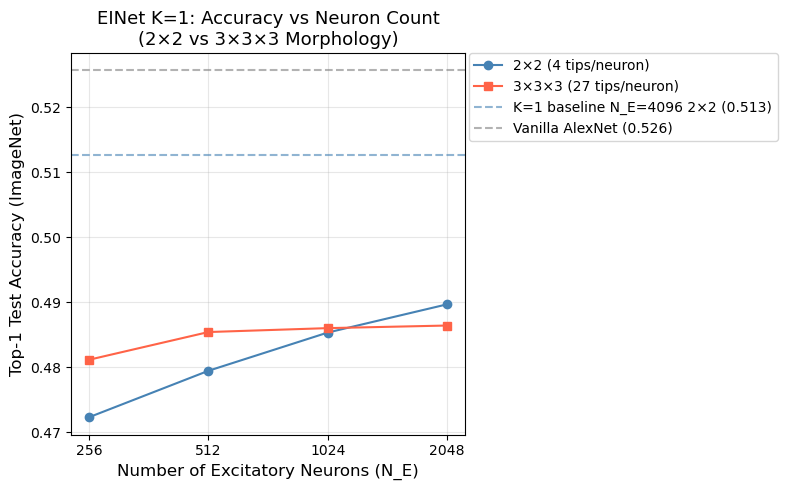

In [2]:
import json
import glob
import matplotlib.pyplot as plt

outputs = "/n/home13/adithyavm/dendritic-modeling/outputs"

def load_test_acc(pattern):
    dirs = sorted(glob.glob(f"{outputs}/{pattern}"))
    if not dirs:
        return None
    perf_file = glob.glob(f"{dirs[-1]}/performance/*.json")[0]
    with open(perf_file) as f:
        return json.load(f)["accuracy"]["test"]

neuron_counts = [256, 512, 1024, 2048]

acc_2x2   = [load_test_acc(f"alexnet_k1_ne{n}_ddp_*")   for n in neuron_counts]
acc_3x3x3 = [load_test_acc(f"alexnet_k1_ne{n}_3x3x3_ddp_*") for n in neuron_counts]

baseline_k1   = load_test_acc("alexnet_k1_einet_ddp_*")
baseline_alex = json.load(open(f"{outputs}/alexnet_baseline/performance.json"))["test"]["top1_accuracy"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(neuron_counts, acc_2x2,   marker='o', label='2×2 (4 tips/neuron)',    color='steelblue')
ax.plot(neuron_counts, acc_3x3x3, marker='s', label='3×3×3 (27 tips/neuron)', color='tomato')

ax.axhline(baseline_k1,   color='steelblue', linestyle='--', alpha=0.6, label=f'K=1 baseline N_E=4096 2×2 ({baseline_k1:.3f})')
ax.axhline(baseline_alex, color='gray',      linestyle='--', alpha=0.6, label=f'Vanilla AlexNet ({baseline_alex:.3f})')

ax.set_xscale('log', base=2)
ax.set_xticks(neuron_counts)
ax.set_xticklabels(neuron_counts)
ax.set_xlabel('Number of Excitatory Neurons (N_E)', fontsize=12)
ax.set_ylabel('Top-1 Test Accuracy (ImageNet)', fontsize=12)
ax.set_title('EINet K=1: Accuracy vs Neuron Count\n(2×2 vs 3×3×3 Morphology)', fontsize=13)
ax.legend(fontsize=10, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
ax.grid(True, alpha=0.3)

plt.tight_layout()


plt.savefig('neuron_sweep_morphology.png', dpi=150, bbox_inches='tight')
plt.show()



In [5]:
from tabulate import tabulate

rows = []
for n, a2, a3 in zip(neuron_counts, acc_2x2, acc_3x3x3):
    rows.append([n, f"{a2:.4f}", f"{a3:.4f}", f"{a3-a2:+.4f}"])

rows.append(["4096 (EI baseline)", f"{baseline_k1:.4f}", "—", "—"])
rows.append(["AlexNet (vanilla)", f"{baseline_alex:.4f}", "—", "—"])

print(tabulate(rows, headers=["N_E", "2×2 Test Acc", "3×3×3 Test Acc", "Δ (3×3×3 − 2×2)"], tablefmt="pretty"))


+--------------------+--------------+----------------+-----------------+
|        N_E         | 2×2 Test Acc | 3×3×3 Test Acc | Δ (3×3×3 − 2×2) |
+--------------------+--------------+----------------+-----------------+
|        256         |    0.4723    |     0.4812     |     +0.0088     |
|        512         |    0.4795    |     0.4854     |     +0.0060     |
|        1024        |    0.4854    |     0.4860     |     +0.0007     |
|        2048        |    0.4897    |     0.4864     |     -0.0033     |
| 4096 (EI baseline) |    0.5127    |       —        |        —        |
| AlexNet (vanilla)  |    0.5257    |       —        |        —        |
+--------------------+--------------+----------------+-----------------+
